# 🏠 House Price Prediction Project (Regression)

**Author:** Muhammad Ali

**Date:**23/October/2026

**Tools Used:** Python, Pandas, Scikit-learn, Random Forest, Matplotlib, Seaborn

**Objective:**
To perform Exploratory Data Analysis (EDA) on the California Housing dataset and build a Machine Learning regression model to accurately predict house prices based on features like median income, location, and house age.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_california_housing


housing = fetch_california_housing()

df = pd.DataFrame(housing.data, columns=housing.feature_names)

df['Price'] = housing.target


print(df.head())
print("\nData ka size:", df.shape)

   MedInc  HouseAge  AveRooms  AveBedrms  Population  AveOccup  Latitude  \
0  8.3252      41.0  6.984127   1.023810       322.0  2.555556     37.88   
1  8.3014      21.0  6.238137   0.971880      2401.0  2.109842     37.86   
2  7.2574      52.0  8.288136   1.073446       496.0  2.802260     37.85   
3  5.6431      52.0  5.817352   1.073059       558.0  2.547945     37.85   
4  3.8462      52.0  6.281853   1.081081       565.0  2.181467     37.85   

   Longitude  Price  
0    -122.23  4.526  
1    -122.22  3.585  
2    -122.24  3.521  
3    -122.25  3.413  
4    -122.25  3.422  

Data ka size: (20640, 9)


Missing values: 0


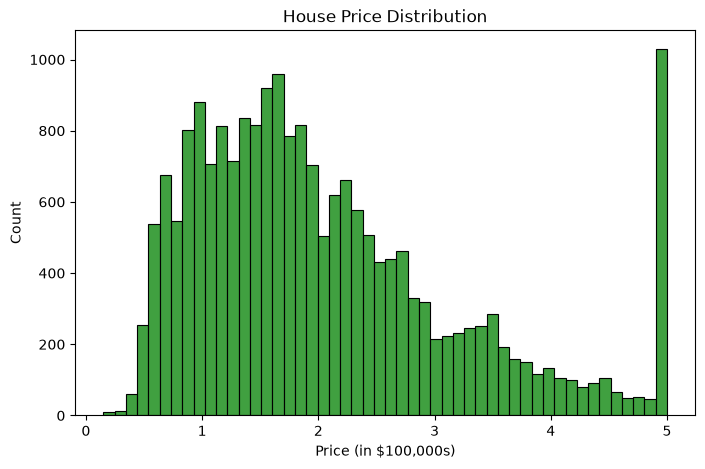

In [ ]:

print("Missing values:", df.isnull().sum().sum())


plt.figure(figsize=(8, 5))
sns.histplot(df['Price'], bins=50, color='green')
plt.title("House Price Distribution")
plt.xlabel("Price (in $100,000s)")
plt.show()

In [ ]:

X = df.drop('Price', axis=1)

y = df['Price']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20640, 8)
Target shape: (20640,)


In [4]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

print(f"Training data: {X_train.shape[0]} rows")
print(f"Testing data: {X_test.shape[0]} rows")

Training data: 16512 rows
Testing data: 4128 rows


In [ ]:
from sklearn.linear_model import LinearRegression


model = LinearRegression()

# Train karo
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Model trained successfully!")
print("Pehle 5 predictions:", y_pred[:5])

Model trained successfully!
Pehle 5 predictions: [0.71912284 1.76401657 2.70965883 2.83892593 2.60465725]


In [6]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("=== Model Evaluation ===")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"R² Score: {r2:.4f}")

=== Model Evaluation ===
MAE:  0.5332
RMSE: 0.7456
R² Score: 0.5758


In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)

rf_mae = mean_absolute_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)

print("=== Random Forest Regression ===")
print(f"MAE: {rf_mae:.4f}")
print(f"R² Score: {rf_r2:.4f}")

=== Random Forest Regression ===
MAE: 0.3277
R² Score: 0.8046


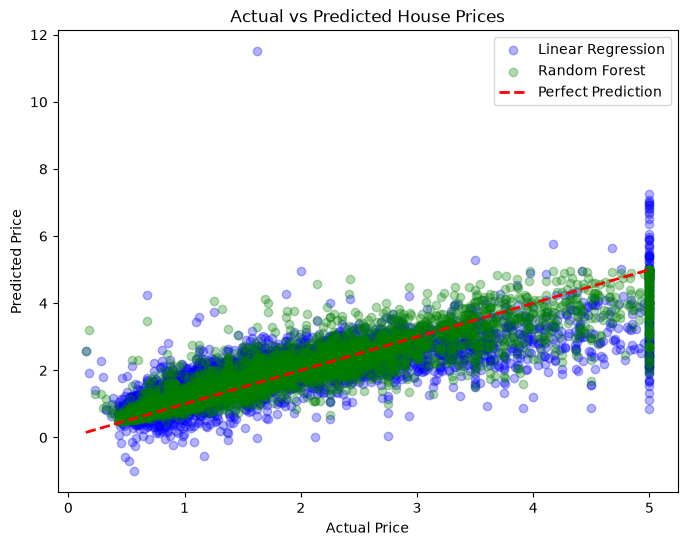

In [8]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, alpha=0.3, color='blue', label='Linear Regression')
plt.scatter(y_test, rf_pred, alpha=0.3, color='green', label='Random Forest')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Perfect Prediction')
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.legend()
plt.title("Actual vs Predicted House Prices")
plt.show()

In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, r2_score

rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

rf_model.fit(X_train, y_train)

rf_pred = rf_model.predict(X_test)


rf_mae = mean_absolute_error(y_test, rf_pred)
rf_r2 = r2_score(y_test, rf_pred)

print("=== Random Forest Regression ===")
print(f"MAE: {rf_mae:.4f}")
print(f"R² Score: {rf_r2:.4f}")

=== Random Forest Regression ===
MAE: 0.3277
R² Score: 0.8046


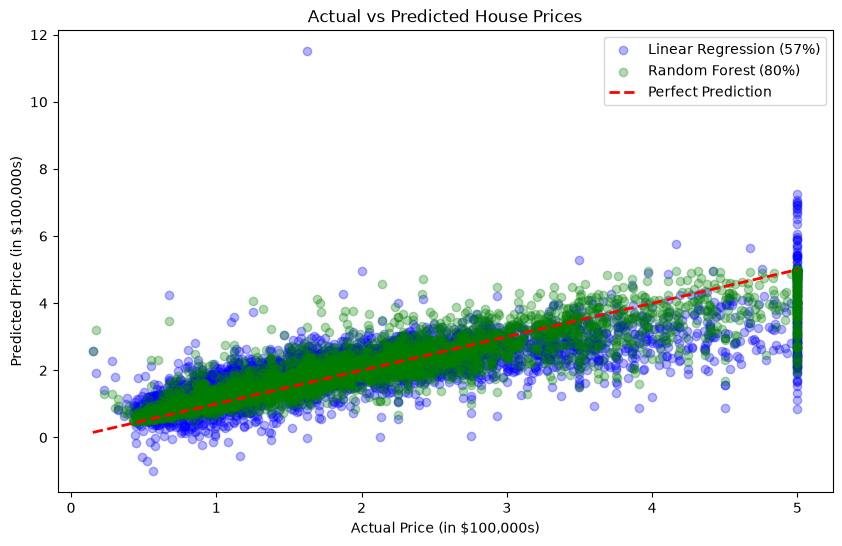

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))


plt.scatter(y_test, y_pred, alpha=0.3, color='blue', label='Linear Regression (57%)')


plt.scatter(y_test, rf_pred, alpha=0.3, color='green', label='Random Forest (80%)')


plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='Perfect Prediction')

plt.xlabel("Actual Price (in $100,000s)")
plt.ylabel("Predicted Price (in $100,000s)")
plt.title("Actual vs Predicted House Prices")
plt.legend()
plt.show()


C:\Users\HP\AppData\Local\Temp\ipykernel_19752\1575915489.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x='Importance', y='Feature', data=feat_imp, palette='viridis')


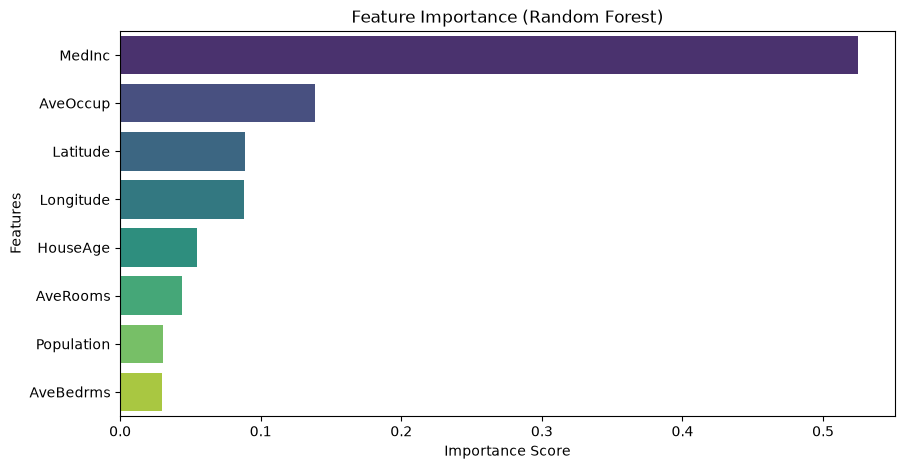

      Feature  Importance
0      MedInc    0.524980
5    AveOccup    0.138367
6    Latitude    0.089035
7   Longitude    0.088474
1    HouseAge    0.054602
2    AveRooms    0.044216
4  Population    0.030662
3   AveBedrms    0.029663


In [ ]:
import pandas as pd


importances = rf_model.feature_importances_

feat_imp = pd.DataFrame({
    'Feature': X.columns,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

plt.figure(figsize=(10, 5))
sns.barplot(x='Importance', y='Feature', data=feat_imp, palette='viridis')
plt.title("Feature Importance (Random Forest)")
plt.xlabel("Importance Score")
plt.ylabel("Features")
plt.show()

print(feat_imp)